# Banking AI Risk Engine

## 1. Data Understanding

### Objective

This notebook explores the datasets used for the Banking AI Risk Engine.

The objectives are to:

- understand the structure of the data
- identify numerical and categorical variables
- investigate missing values
- identify duplicates
- examine the target variable
- investigate potential outliers
- identify potential data leakage
- assess whether the data is suitable for machine learning

In [1]:
import pandas as pd
import numpy as np
from numba.core.types import none

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [2]:
import pandas as pd
data_path="../data/raw/german.data"
df = pd.read_csv(data_path, sep=r"\s+", header=None,engine="python")
print(df.shape)


(1000, 21)


In [3]:
df.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,4,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,2,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,3,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,4,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,4,A124,53,A143,A153,2,A173,2,A191,A201,2


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   0       1000 non-null   object
 1   1       1000 non-null   int64 
 2   2       1000 non-null   object
 3   3       1000 non-null   object
 4   4       1000 non-null   int64 
 5   5       1000 non-null   object
 6   6       1000 non-null   object
 7   7       1000 non-null   int64 
 8   8       1000 non-null   object
 9   9       1000 non-null   object
 10  10      1000 non-null   int64 
 11  11      1000 non-null   object
 12  12      1000 non-null   int64 
 13  13      1000 non-null   object
 14  14      1000 non-null   object
 15  15      1000 non-null   int64 
 16  16      1000 non-null   object
 17  17      1000 non-null   int64 
 18  18      1000 non-null   object
 19  19      1000 non-null   object
 20  20      1000 non-null   int64 
dtypes: int64(8), object(13)
memory usage: 164.2+ KB


In [5]:
df.isnull().sum()

0     0
1     0
2     0
3     0
4     0
5     0
6     0
7     0
8     0
9     0
10    0
11    0
12    0
13    0
14    0
15    0
16    0
17    0
18    0
19    0
20    0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
columns = [
    "checking_account",
    "duration_months",
    "credit_history",
    "purpose",
    "credit_amount",
    "savings_account",
    "employment",
    "installment_rate",
    "personal_status_sex",
    "other_debtors",
    "residence_since",
    "property",
    "age",
    "other_installment_plans",
    "housing",
    "existing_credits",
    "job",
    "dependents",
    "telephone",
    "foreign_worker",
    "credit_risk"
]

df.columns = columns

print(df.shape)
df.head()

(1000, 21)


,checking_account,duration_months,credit_history,purpose,credit_amount,savings_account,employment,installment_rate,personal_status_sex,other_debtors,residence_since,property,age,other_installment_plans,housing,existing_credits,job,dependents,telephone,foreign_worker,credit_risk
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,4,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,2,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,3,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,4,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,4,A124,53,A143,A153,2,A173,2,A191,A201,2


In [8]:
df["credit_risk"].value_counts()

credit_risk
1    700
2    300
Name: count, dtype: int64

In [9]:
df["credit_risk"].value_counts(normalize=True)

credit_risk
1    0.7
2    0.3
Name: proportion, dtype: float64

In [10]:
for column in df.columns:
    print("\n", column)
    print(df[column].unique())


 checking_account
['A11' 'A12' 'A14' 'A13']

 duration_months
[ 6 48 12 42 24 36 30 15  9 10  7 60 18 45 11 27  8 54 20 14 33 21 16  4
 47 13 22 39 28  5 26 72 40]

 credit_history
['A34' 'A32' 'A33' 'A30' 'A31']

 purpose
['A43' 'A46' 'A42' 'A40' 'A41' 'A49' 'A44' 'A45' 'A410' 'A48']

 credit_amount
[ 1169  5951  2096  7882  4870  9055  2835  6948  3059  5234  1295  4308
  1567  1199  1403  1282  2424  8072 12579  3430  2134  2647  2241  1804
  2069  1374   426   409  2415  6836  1913  4020  5866  1264  1474  4746
  6110  2100  1225   458  2333  1158  6204  6187  6143  1393  2299  1352
  7228  2073  5965  1262  3378  2225   783  6468  9566  1961  6229  1391
  1537  1953 14421  3181  5190  2171  1007  1819  2394  8133   730  1164
  5954  1977  1526  3965  4771  9436  3832  5943  1213  1568  1755  2315
  1412 12612  2249  1108   618  1409   797  3617  1318 15945  2012  2622
  2337  7057  1469  2323   932  1919  2445 11938  6458  6078  7721  1410
  1449   392  6260  7855  1680  3578  71

In [11]:
df.dtypes

checking_account           object
duration_months             int64
credit_history             object
purpose                    object
credit_amount               int64
savings_account            object
employment                 object
installment_rate            int64
personal_status_sex        object
other_debtors              object
residence_since             int64
property                   object
age                         int64
other_installment_plans    object
housing                    object
existing_credits            int64
job                        object
dependents                  int64
telephone                  object
foreign_worker             object
credit_risk                 int64
dtype: object

In [12]:
df.describe()

,duration_months,credit_amount,installment_rate,residence_since,age,existing_credits,dependents,credit_risk
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,20.903000,3271.258000,2.973000,2.845000,35.546000,1.407000,1.155000,1.300000
std,12.058814,2822.736876,1.118715,1.103718,11.375469,0.577654,0.362086,0.458487
min,4.000000,250.000000,1.000000,1.000000,19.000000,1.000000,1.000000,1.000000
25%,12.000000,1365.500000,2.000000,2.000000,27.000000,1.000000,1.000000,1.000000
50%,18.000000,2319.500000,3.000000,3.000000,33.000000,1.000000,1.000000,1.000000
75%,24.000000,3972.250000,4.000000,4.000000,42.000000,2.000000,1.000000,2.000000
max,72.000000,18424.000000,4.000000,4.000000,75.000000,4.000000,2.000000,2.000000


In [13]:
df.describe(include="object")

,checking_account,credit_history,purpose,savings_account,employment,personal_status_sex,other_debtors,property,other_installment_plans,housing,job,telephone,foreign_worker
count,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000
unique,4,5,10,5,5,4,3,4,3,3,4,2,2
top,A14,A32,A43,A61,A73,A93,A101,A123,A143,A152,A173,A191,A201
freq,394,530,280,603,339,548,907,332,814,713,630,596,963


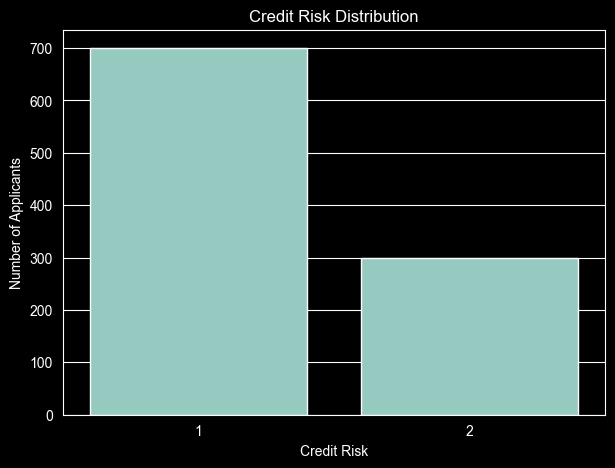

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="credit_risk")
plt.title("Credit Risk Distribution")
plt.xlabel("Credit Risk")
plt.ylabel("Number of Applicants")
plt.show()

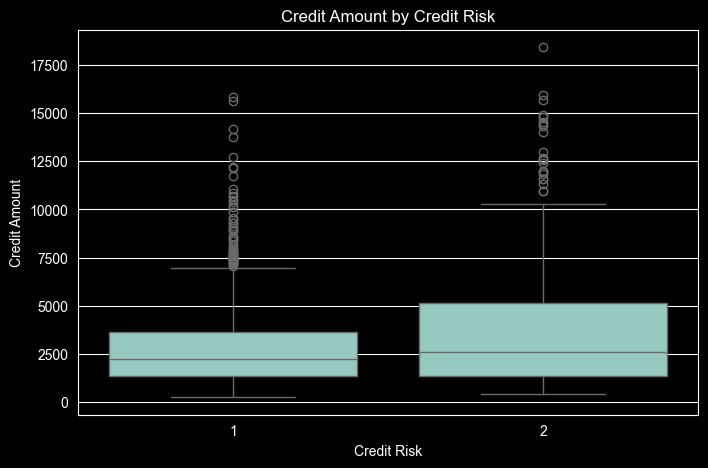

In [15]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="credit_risk", y="credit_amount")
plt.title("Credit Amount by Credit Risk")
plt.xlabel("Credit Risk")
plt.ylabel("Credit Amount")
plt.show()

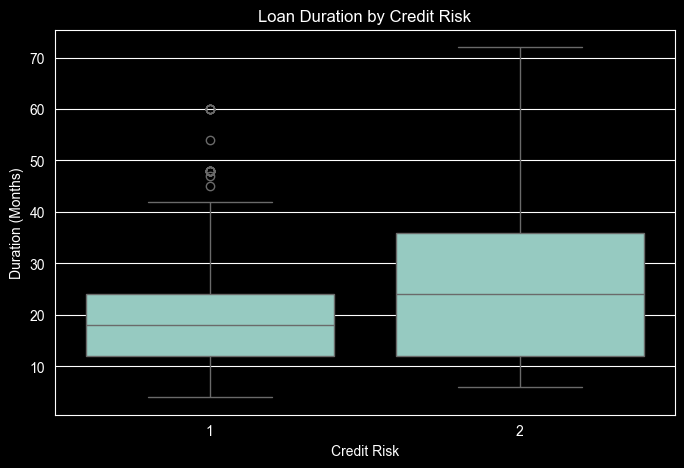

In [16]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="credit_risk", y="duration_months")
plt.title("Loan Duration by Credit Risk")
plt.xlabel("Credit Risk")
plt.ylabel("Duration (Months)")
plt.show()

In [17]:
risk_summary = df.groupby("credit_risk").agg(
    average_credit_amount=("credit_amount", "mean"),
    median_credit_amount=("credit_amount", "median"),
    average_duration=("duration_months", "mean"),
    median_duration=("duration_months", "median"),
    average_age=("age", "mean")
)

risk_summary

,average_credit_amount,median_credit_amount,average_duration,median_duration,average_age
credit_risk,,,,,
1,2985.457143,2244.0,19.207143,18.0,36.224286
2,3938.126667,2574.5,24.860000,24.0,33.963333


In [18]:
risk_summary.loc[2] - risk_summary.loc[1]

average_credit_amount    952.669524
median_credit_amount     330.500000
average_duration           5.652857
median_duration            6.000000
average_age               -2.260952
dtype: float64

In [19]:
pd.crosstab(
    df["checking_account"],
    df["credit_risk"],
    normalize="index"
)

credit_risk,1,2
checking_account,,
A11,0.507299,0.492701
A12,0.609665,0.390335
A13,0.777778,0.222222
A14,0.883249,0.116751


In [20]:
pd.crosstab(
    df["credit_history"],
    df["credit_risk"],
    normalize="index"
)

credit_risk,1,2
credit_history,,
A30,0.375000,0.625000
A31,0.428571,0.571429
A32,0.681132,0.318868
A33,0.681818,0.318182
A34,0.829352,0.170648


In [21]:
pd.crosstab(
    df["savings_account"],
    df["credit_risk"],
    normalize="index"
)

credit_risk,1,2
savings_account,,
A61,0.640133,0.359867
A62,0.669903,0.330097
A63,0.825397,0.174603
A64,0.875000,0.125000
A65,0.825137,0.174863


In [22]:
pd.crosstab(
    df["employment"],
    df["credit_risk"],
    normalize="index"
)

credit_risk,1,2
employment,,
A71,0.629032,0.370968
A72,0.593023,0.406977
A73,0.693215,0.306785
A74,0.775862,0.224138
A75,0.747036,0.252964


In [23]:
def risk_distribution(column):
    return pd.crosstab(
        df[column],
        df["credit_risk"],
        normalize="index"
    ).round(3)

In [24]:
risk_distribution("purpose")

credit_risk,1,2
purpose,,
A40,0.620,0.380
A41,0.835,0.165
A410,0.583,0.417
A42,0.680,0.320
A43,0.779,0.221
A44,0.667,0.333
A45,0.636,0.364
A46,0.560,0.440
A48,0.889,0.111


In [25]:
risk_distribution("housing")

credit_risk,1,2
housing,,
A151,0.609,0.391
A152,0.739,0.261
A153,0.593,0.407


In [26]:
risk_distribution("job")

credit_risk,1,2
job,,
A171,0.682,0.318
A172,0.720,0.280
A173,0.705,0.295
A174,0.655,0.345


In [27]:
numeric_cols = [
    "duration_months",
    "credit_amount",
    "installment_rate",
    "residence_since",
    "age",
    "existing_credits",
    "dependents",
    "credit_risk"
]

correlation_matrix = df[numeric_cols].corr()

correlation_matrix

,duration_months,credit_amount,installment_rate,residence_since,age,existing_credits,dependents,credit_risk
duration_months,1.000000,0.624984,0.074749,0.034067,-0.036136,-0.011284,-0.023834,0.214927
credit_amount,0.624984,1.000000,-0.271316,0.028926,0.032716,0.020795,0.017142,0.154739
installment_rate,0.074749,-0.271316,1.000000,0.049302,0.058266,0.021669,-0.071207,0.072404
residence_since,0.034067,0.028926,0.049302,1.000000,0.266419,0.089625,0.042643,0.002967
age,-0.036136,0.032716,0.058266,0.266419,1.000000,0.149254,0.118201,-0.091127
existing_credits,-0.011284,0.020795,0.021669,0.089625,0.149254,1.000000,0.109667,-0.045732
dependents,-0.023834,0.017142,-0.071207,0.042643,0.118201,0.109667,1.000000,-0.003015
credit_risk,0.214927,0.154739,0.072404,0.002967,-0.091127,-0.045732,-0.003015,1.000000


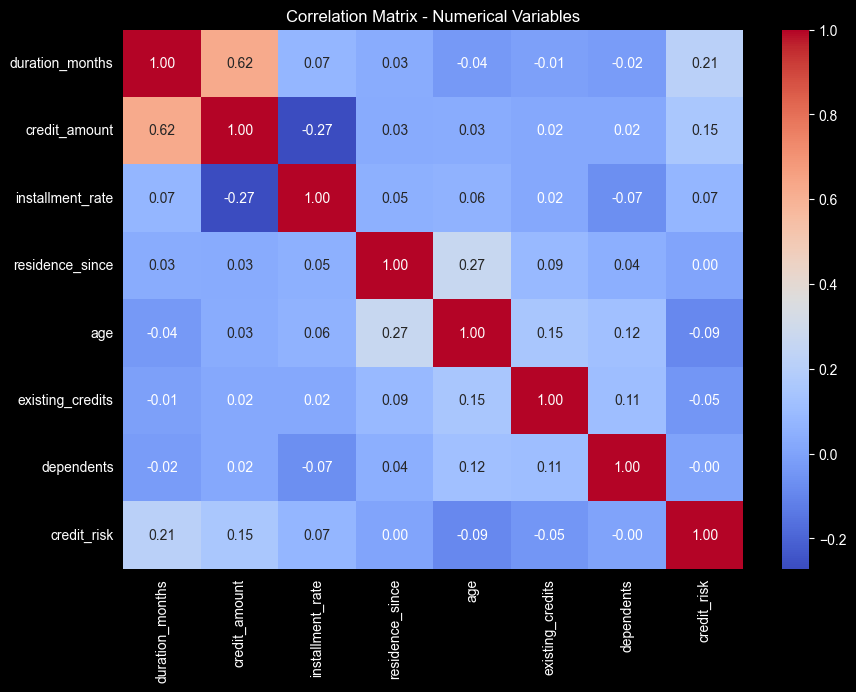

In [28]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Matrix - Numerical Variables")
plt.show()

In [29]:
df.head()

,checking_account,duration_months,credit_history,purpose,credit_amount,savings_account,employment,installment_rate,personal_status_sex,other_debtors,residence_since,property,age,other_installment_plans,housing,existing_credits,job,dependents,telephone,foreign_worker,credit_risk
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,4,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,2,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,3,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,4,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,4,A124,53,A143,A153,2,A173,2,A191,A201,2


In [30]:
df.dtypes

checking_account           object
duration_months             int64
credit_history             object
purpose                    object
credit_amount               int64
savings_account            object
employment                 object
installment_rate            int64
personal_status_sex        object
other_debtors              object
residence_since             int64
property                   object
age                         int64
other_installment_plans    object
housing                    object
existing_credits            int64
job                        object
dependents                  int64
telephone                  object
foreign_worker             object
credit_risk                 int64
dtype: object

In [31]:
df_decoded = df.copy()

In [32]:
# Checking account
df_decoded["checking_account"] = df_decoded["checking_account"].map({
    "A11": "< 0 DM",
    "A12": "0 - 200 DM",
    "A13": ">= 200 DM",
    "A14": "No checking account"
})

# Credit history
df_decoded["credit_history"] = df_decoded["credit_history"].map({
    "A30": "No credits / all paid duly",
    "A31": "All previous credits at this bank paid duly",
    "A32": "Existing credits paid duly",
    "A33": "Delay in previous credit payments",
    "A34": "Critical account / other existing credits"
})

# Purpose
df_decoded["purpose"] = df_decoded["purpose"].map({
    "A40": "New car",
    "A41": "Used car",
    "A42": "Furniture/equipment",
    "A43": "Radio/television",
    "A44": "Domestic appliances",
    "A45": "Repairs",
    "A46": "Education",
    "A47": "Vacation",
    "A48": "Retraining",
    "A49": "Business",
    "A410": "Other"
})

# Savings
df_decoded["savings_account"] = df_decoded["savings_account"].map({
    "A61": "< 100 DM",
    "A62": "100 - 500 DM",
    "A63": "500 - 1000 DM",
    "A64": ">= 1000 DM",
    "A65": "Unknown / no savings account"
})

# Employment
df_decoded["employment"] = df_decoded["employment"].map({
    "A71": "Unemployed",
    "A72": "< 1 year",
    "A73": "1 - 4 years",
    "A74": "4 - 7 years",
    "A75": ">= 7 years"
})

# Personal status / sex
df_decoded["personal_status_sex"] = df_decoded["personal_status_sex"].map({
    "A91": "Male - divorced/separated",
    "A92": "Female - divorced/separated/married",
    "A93": "Male - single",
    "A94": "Male - married/widowed"
})

# Other debtors
df_decoded["other_debtors"] = df_decoded["other_debtors"].map({
    "A101": "None",
    "A102": "Co-applicant",
    "A103": "Guarantor"
})

# Property
df_decoded["property"] = df_decoded["property"].map({
    "A121": "Real estate",
    "A122": "Building society savings / life insurance",
    "A123": "Car or other property",
    "A124": "Unknown / no property"
})

# Other installment plans
df_decoded["other_installment_plans"] = df_decoded["other_installment_plans"].map({
    "A141": "Bank",
    "A142": "Stores",
    "A143": "None"
})

# Housing
df_decoded["housing"] = df_decoded["housing"].map({
    "A151": "Rent",
    "A152": "Own",
    "A153": "For free"
})

# Job
df_decoded["job"] = df_decoded["job"].map({
    "A171": "Unemployed / unskilled non-resident",
    "A172": "Unskilled resident",
    "A173": "Skilled employee / official",
    "A174": "Management / self-employed / highly qualified / officer"
})

# Telephone
df_decoded["telephone"] = df_decoded["telephone"].map({
    "A191": "None",
    "A192": "Yes - registered under customer's name"
})

# Foreign worker
df_decoded["foreign_worker"] = df_decoded["foreign_worker"].map({
    "A201": "Yes",
    "A202": "No"
})

print("Categorical variables decoded successfully.")

Categorical variables decoded successfully.


In [33]:
df_model = df_decoded.copy()

df_model["target"] = df_model["credit_risk"].map({
    1: 0,   # Good credit
    2: 1    # Bad credit
})

df_model[["credit_risk", "target"]].head(10)

,credit_risk,target
0,1,0
1,2,1
2,1,0
3,1,0
4,2,1
5,1,0
6,1,0
7,1,0
8,1,0
9,2,1


In [34]:
target_counts = df_model["target"].value_counts().sort_index()

target_counts

target
0    700
1    300
Name: count, dtype: int64

In [35]:
target_percentages = (
    df_model["target"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

target_percentages

target
0    70.0
1    30.0
Name: proportion, dtype: float64

In [36]:
X = df_model.drop(columns=["credit_risk", "target"])
y = df_model["target"]

In [37]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1000, 20)
y shape: (1000,)


In [38]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [39]:
print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).sort_index())

print("\nTest target distribution:")
print(y_test.value_counts(normalize=True).sort_index())

Training set: (800, 20)
Test set: (200, 20)

Training target distribution:
target
0    0.7
1    0.3
Name: proportion, dtype: float64

Test target distribution:
target
0    0.7
1    0.3
Name: proportion, dtype: float64


In [40]:
categorical_features = [
    "checking_account",
    "credit_history",
    "purpose",
    "savings_account",
    "employment",
    "personal_status_sex",
    "other_debtors",
    "property",
    "other_installment_plans",
    "housing",
    "job",
    "telephone",
    "foreign_worker"
]

numerical_features = [
    "duration_months",
    "credit_amount",
    "installment_rate",
    "residence_since",
    "age",
    "existing_credits",
    "dependents"
]

In [41]:
print("Categorical features:", len(categorical_features))
print("Numerical features:", len(numerical_features))
print("Total features:", len(categorical_features) + len(numerical_features))

Categorical features: 13
Numerical features: 7
Total features: 20


In [42]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        )
    ]
)

In [43]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

In [44]:
print("Processed training shape:", X_train_processed.shape)
print("Processed test shape:", X_test_processed.shape)

Processed training shape: (800, 61)
Processed test shape: (200, 61)


In [45]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(
    X_train_processed,
    y_train
)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [46]:
y_pred_logistic = logistic_model.predict(X_test_processed)

print(y_pred_logistic[:20])

[0 0 1 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0]


In [47]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

accuracy = accuracy_score(y_test, y_pred_logistic)
precision = precision_score(y_test, y_pred_logistic)
recall = recall_score(y_test, y_pred_logistic)
f1 = f1_score(y_test, y_pred_logistic)

y_prob_logistic = logistic_model.predict_proba(X_test_processed)[:, 1]

roc_auc = roc_auc_score(
    y_test,
    y_prob_logistic
)

print(f"Accuracy:  {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall:    {recall:.3f}")
print(f"F1 Score:  {f1:.3f}")
print(f"ROC-AUC:   {roc_auc:.3f}")

Accuracy:  0.780
Precision: 0.667
Recall:    0.533
F1 Score:  0.593
ROC-AUC:   0.804


In [48]:
y_prob_logistic[:10]

array([0.22680794, 0.10145826, 0.61876846, 0.49335708, 0.15016187,
       0.11255578, 0.21671203, 0.11332271, 0.48857598, 0.15060426])

In [49]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred_logistic)

print(cm)

[[124  16]
 [ 28  32]]


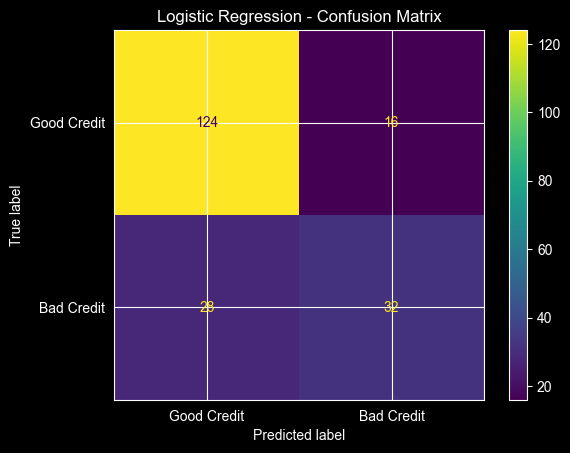

In [50]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Good Credit", "Bad Credit"]
)

disp.plot()
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [51]:
from sklearn.ensemble import RandomForestClassifier

random_forest = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=5,
    random_state=42,
    n_jobs=-1
)

random_forest.fit(
    X_train_processed,
    y_train
)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [52]:
y_pred_rf = random_forest.predict(X_test_processed)

y_prob_rf = random_forest.predict_proba(
    X_test_processed
)[:, 1]

In [53]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)
rf_roc_auc = roc_auc_score(y_test, y_prob_rf)

print(f"Accuracy:  {rf_accuracy:.3f}")
print(f"Precision: {rf_precision:.3f}")
print(f"Recall:    {rf_recall:.3f}")
print(f"F1 Score:  {rf_f1:.3f}")
print(f"ROC-AUC:   {rf_roc_auc:.3f}")

Accuracy:  0.780
Precision: 0.722
Recall:    0.433
F1 Score:  0.542
ROC-AUC:   0.792


In [54]:
from sklearn.metrics import confusion_matrix

cm_rf = confusion_matrix(y_test, y_pred_rf)

print(cm_rf)

[[130  10]
 [ 34  26]]


In [55]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss"
)

xgb_model.fit(
    X_train_processed,
    y_train
)

y_pred_xgb = xgb_model.predict(X_test_processed)
y_prob_xgb = xgb_model.predict_proba(X_test_processed)[:, 1]

In [56]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

xgb_accuracy = accuracy_score(y_test, y_pred_xgb)
xgb_precision = precision_score(y_test, y_pred_xgb)
xgb_recall = recall_score(y_test, y_pred_xgb)
xgb_f1 = f1_score(y_test, y_pred_xgb)
xgb_roc_auc = roc_auc_score(y_test, y_prob_xgb)

print("XGBoost Results")
print("----------------")
print("Accuracy :", xgb_accuracy)
print("Precision:", xgb_precision)
print("Recall   :", xgb_recall)
print("F1 Score :", xgb_f1)
print("ROC-AUC  :", xgb_roc_auc)

XGBoost Results
----------------
Accuracy : 0.76
Precision: 0.6428571428571429
Recall   : 0.45
F1 Score : 0.5294117647058824
ROC-AUC  : 0.781904761904762


In [57]:
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]

results = []

for threshold in thresholds:
    y_pred_threshold = (y_prob_logistic >= threshold).astype(int)

    results.append({
        "threshold": threshold,
        "precision": precision_score(y_test, y_pred_threshold),
        "recall": recall_score(y_test, y_pred_threshold),
        "f1": f1_score(y_test, y_pred_threshold)
    })

threshold_results = pd.DataFrame(results)

threshold_results

,threshold,precision,recall,f1
0,0.2,0.458716,0.833333,0.591716
1,0.3,0.563218,0.816667,0.666667
2,0.4,0.632353,0.716667,0.671875
3,0.5,0.666667,0.533333,0.592593
4,0.6,0.705882,0.400000,0.510638
5,0.7,0.714286,0.250000,0.370370


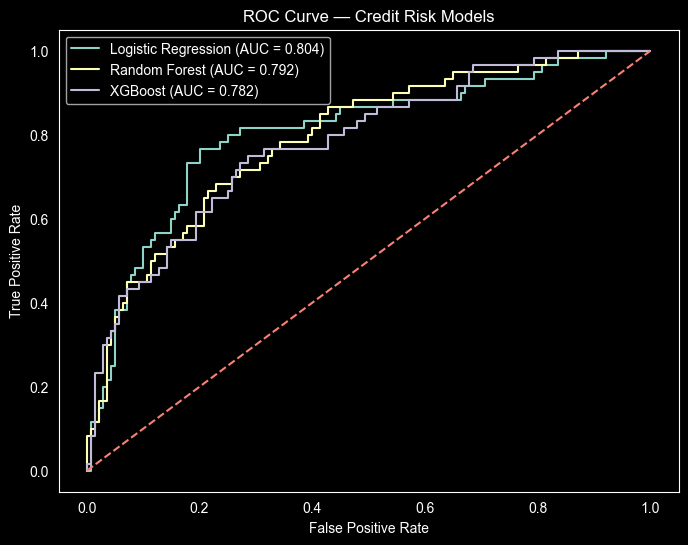

In [58]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr_log, tpr_log, _ = roc_curve(y_test, y_prob_logistic)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_prob_xgb)

plt.figure(figsize=(8, 6))

plt.plot(fpr_log, tpr_log, label="Logistic Regression (AUC = 0.804)")
plt.plot(fpr_rf, tpr_rf, label="Random Forest (AUC = 0.792)")
plt.plot(fpr_xgb, tpr_xgb, label="XGBoost (AUC = 0.782)")

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Credit Risk Models")
plt.legend()
plt.grid()

plt.show()

In [59]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = cross_validate(
    logistic_model,
    X_train_processed,
    y_train,
    cv=cv,
    scoring=[
        "accuracy",
        "precision",
        "recall",
        "f1",
        "roc_auc"
    ]
)

print("Cross-validation results:")
print("Accuracy :", cv_results["test_accuracy"].mean())
print("Precision:", cv_results["test_precision"].mean())
print("Recall   :", cv_results["test_recall"].mean())
print("F1       :", cv_results["test_f1"].mean())
print("ROC-AUC  :", cv_results["test_roc_auc"].mean())

Cross-validation results:
Accuracy : 0.7375
Precision: 0.5832973034474912
Recall   : 0.4333333333333334
F1       : 0.49398583666448453
ROC-AUC  : 0.7707589285714286


In [60]:
from sklearn.pipeline import Pipeline

logistic_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]
)

In [61]:
cv_results = cross_validate(
    logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=[
        "accuracy",
        "precision",
        "recall",
        "f1",
        "roc_auc"
    ]
)

print("Pipeline Cross-validation results:")
print("Accuracy :", cv_results["test_accuracy"].mean())
print("Precision:", cv_results["test_precision"].mean())
print("Recall   :", cv_results["test_recall"].mean())
print("F1       :", cv_results["test_f1"].mean())
print("ROC-AUC  :", cv_results["test_roc_auc"].mean())

Pipeline Cross-validation results:
Accuracy : 0.7375
Precision: 0.5832973034474912
Recall   : 0.4333333333333334
F1       : 0.49398583666448453
ROC-AUC  : 0.7705729166666666


In [62]:
print("ROC-AUC scores for each fold:")
print(cv_results["test_roc_auc"])

print("\nMean ROC-AUC:")
print(cv_results["test_roc_auc"].mean())

print("\nStandard deviation:")
print(cv_results["test_roc_auc"].std())

ROC-AUC scores for each fold:
[0.80840774 0.83110119 0.75837054 0.67578125 0.77920387]

Mean ROC-AUC:
0.7705729166666666

Standard deviation:
0.05348644155717658


In [63]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

random_forest_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=300,
            max_depth=None,
            min_samples_split=5,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

In [64]:
from xgboost import XGBClassifier

xgb_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", XGBClassifier(
            n_estimators=300,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=42,
            eval_metric="logloss"
        ))
    ]
)

In [65]:
rf_cv_results = cross_validate(
    random_forest_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=[
        "accuracy",
        "precision",
        "recall",
        "f1",
        "roc_auc"
    ]
)

print("Random Forest CV")
print("----------------")
print("Accuracy :", rf_cv_results["test_accuracy"].mean())
print("Precision:", rf_cv_results["test_precision"].mean())
print("Recall   :", rf_cv_results["test_recall"].mean())
print("F1       :", rf_cv_results["test_f1"].mean())
print("ROC-AUC  :", rf_cv_results["test_roc_auc"].mean())

Random Forest CV
----------------
Accuracy : 0.7550000000000001
Precision: 0.6540949277723472
Recall   : 0.375
F1       : 0.47390201556221195
ROC-AUC  : 0.7962797619047619


In [66]:
xgb_cv_results = cross_validate(
    xgb_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=[
        "accuracy",
        "precision",
        "recall",
        "f1",
        "roc_auc"
    ]
)

print("XGBoost CV")
print("-----------")
print("Accuracy :", xgb_cv_results["test_accuracy"].mean())
print("Precision:", xgb_cv_results["test_precision"].mean())
print("Recall   :", xgb_cv_results["test_recall"].mean())
print("F1       :", xgb_cv_results["test_f1"].mean())
print("ROC-AUC  :", xgb_cv_results["test_roc_auc"].mean())

XGBoost CV
-----------
Accuracy : 0.76
Precision: 0.6307398307398308
Recall   : 0.475
F1       : 0.5406660441954559
ROC-AUC  : 0.7941220238095238


In [67]:
from sklearn.model_selection import GridSearchCV

logistic_param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100]
}

logistic_grid = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=logistic_param_grid,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

logistic_grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__C': [0.01, 0.1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displayed;

In [68]:
print("Best parameters:")
print(logistic_grid.best_params_)

print("\nBest cross-validation ROC-AUC:")
print(logistic_grid.best_score_)

Best parameters:
{'model__C': 0.1}

Best cross-validation ROC-AUC:
0.7838169642857145


In [69]:
rf_param_grid = {
    "model__n_estimators": [200, 300],
    "model__max_depth": [None, 5, 10],
    "model__min_samples_split": [2, 5]
}

In [71]:
rf_grid = GridSearchCV(
    estimator=random_forest_pipeline,
    param_grid=rf_param_grid,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__max_depth': [None, 5, ...], 'model__min_samples_split': [2, 5], 'model__n_estimators': [200, 300]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each 

In [72]:
print("Best Random Forest parameters:")
print(rf_grid.best_params_)

print("\nBest cross-validation ROC-AUC:")
print(rf_grid.best_score_)

Best Random Forest parameters:
{'model__max_depth': None, 'model__min_samples_split': 5, 'model__n_estimators': 200}

Best cross-validation ROC-AUC:
0.7979166666666666


In [73]:
xgb_param_grid = {
    "model__n_estimators": [200, 300],
    "model__max_depth": [3, 4, 6],
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__subsample": [0.8, 1.0]
}

xgb_grid = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=xgb_param_grid,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

xgb_grid.fit(X_train, y_train)

print("Best XGBoost parameters:")
print(xgb_grid.best_params_)

print("\nBest cross-validation ROC-AUC:")
print(xgb_grid.best_score_)

Best XGBoost parameters:
{'model__learning_rate': 0.05, 'model__max_depth': 4, 'model__n_estimators': 200, 'model__subsample': 0.8}

Best cross-validation ROC-AUC:
0.7980654761904761


In [74]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

models = {
    "Logistic Regression": logistic_grid.best_estimator_,
    "Random Forest": rf_grid.best_estimator_,
    "XGBoost": xgb_grid.best_estimator_
}

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    print(f"\n{name}")
    print("-" * 40)
    print("Accuracy :", round(accuracy_score(y_test, y_pred), 3))
    print("Precision:", round(precision_score(y_test, y_pred), 3))
    print("Recall   :", round(recall_score(y_test, y_pred), 3))
    print("F1       :", round(f1_score(y_test, y_pred), 3))
    print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob), 3))
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))


Logistic Regression
----------------------------------------
Accuracy : 0.79
Precision: 0.714
Recall   : 0.5
F1       : 0.588
ROC-AUC  : 0.81
Confusion Matrix:
[[128  12]
 [ 30  30]]

Random Forest
----------------------------------------
Accuracy : 0.77
Precision: 0.694
Recall   : 0.417
F1       : 0.521
ROC-AUC  : 0.787
Confusion Matrix:
[[129  11]
 [ 35  25]]

XGBoost
----------------------------------------
Accuracy : 0.775
Precision: 0.683
Recall   : 0.467
F1       : 0.554
ROC-AUC  : 0.786
Confusion Matrix:
[[127  13]
 [ 32  28]]


In [75]:
import shap

print("SHAP version:", shap.__version__)

SHAP version: 0.52.0


In [76]:
final_logistic_model = logistic_grid.best_estimator_

print(final_logistic_model)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['checking_account',
                                                   'credit_history', 'purpose',
                                                   'savings_account',
                                                   'employment',
                                                   'personal_status_sex',
                                                   'other_debtors', 'property',
                                                   'other_installment_plans',
                                                   'housing', 'job',
                                                   'telephone',
                                                   'foreign_worker']),
                                                 ('numerical', StandardScaler(),
         

In [77]:
X_test_processed_final = (
    final_logistic_model
    .named_steps["preprocessor"]
    .transform(X_test)
)

print("Processed test shape:", X_test_processed_final.shape)

Processed test shape: (200, 61)


In [79]:
explainer = shap.LinearExplainer(
    final_logistic_model.named_steps["model"],
    shap.maskers.Independent(X_test_processed_final, max_samples=200)
)

shap_values = explainer.shap_values(X_test_processed_final)

print("SHAP values shape:", shap_values.shape)

SHAP values shape: (200, 61)


In [80]:
feature_names = (
    final_logistic_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

print("Number of feature names:", len(feature_names))
print(feature_names)

Number of feature names: 61
['categorical__checking_account_0 - 200 DM'
 'categorical__checking_account_< 0 DM'
 'categorical__checking_account_>= 200 DM'
 'categorical__checking_account_No checking account'
 'categorical__credit_history_All previous credits at this bank paid duly'
 'categorical__credit_history_Critical account / other existing credits'
 'categorical__credit_history_Delay in previous credit payments'
 'categorical__credit_history_Existing credits paid duly'
 'categorical__credit_history_No credits / all paid duly'
 'categorical__purpose_Business'
 'categorical__purpose_Domestic appliances'
 'categorical__purpose_Education'
 'categorical__purpose_Furniture/equipment' 'categorical__purpose_New car'
 'categorical__purpose_Other' 'categorical__purpose_Radio/television'
 'categorical__purpose_Repairs' 'categorical__purpose_Retraining'
 'categorical__purpose_Used car'
 'categorical__savings_account_100 - 500 DM'
 'categorical__savings_account_500 - 1000 DM'
 'categorical__sa

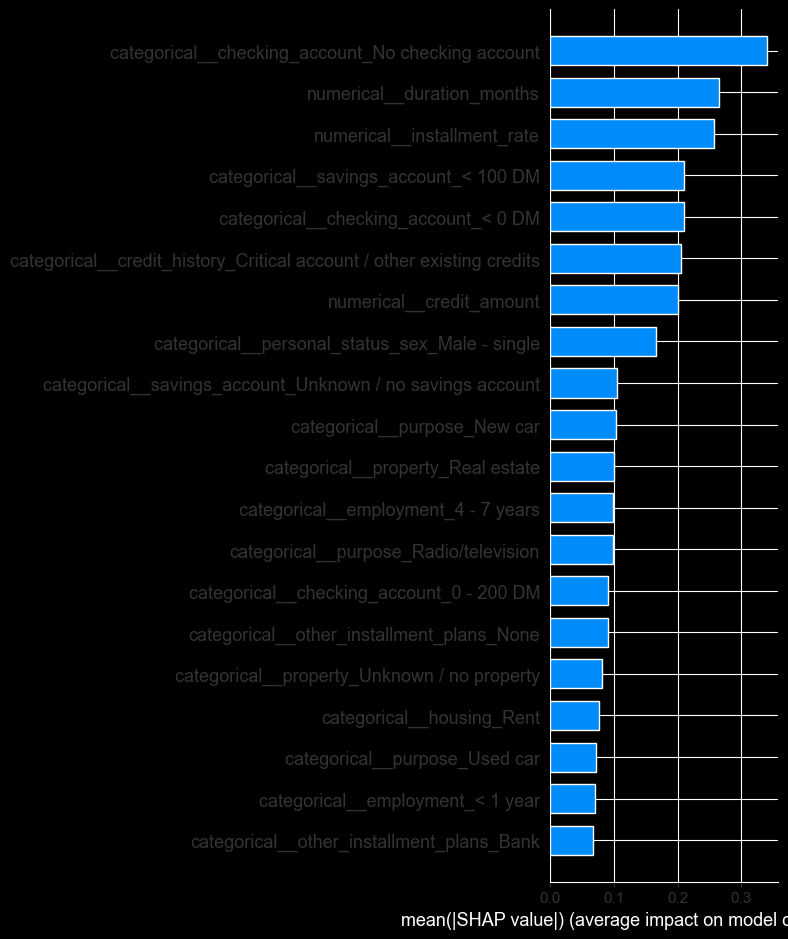

In [81]:
shap.summary_plot(
    shap_values,
    X_test_processed_final,
    feature_names=feature_names,
    plot_type="bar"
)

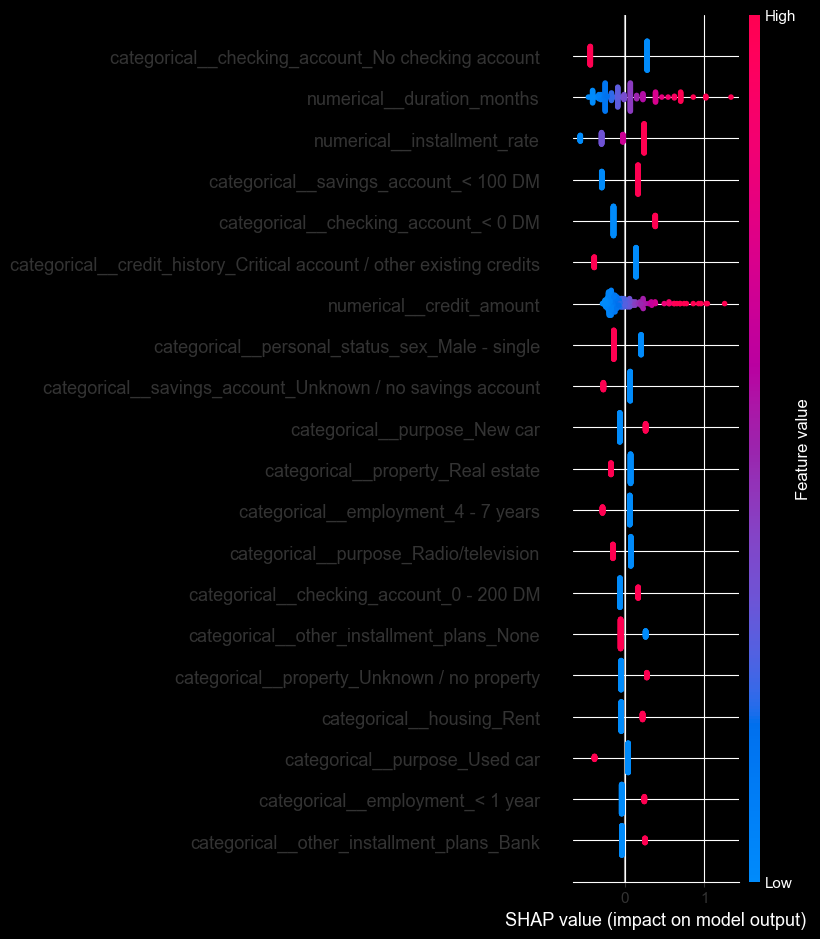

In [82]:
shap.summary_plot(
    shap_values,
    X_test_processed_final,
    feature_names=feature_names
)

In [87]:
import numpy as np
import pandas as pd

# Get transformed feature names directly from the fitted preprocessor
feature_names = (
    final_logistic_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

# Create mapping from each transformed feature to its original feature
feature_mapping = []

for name in feature_names:

    if name.startswith("numerical__"):
        original_feature = name.replace("numerical__", "", 1)

    elif name.startswith("categorical__"):
        remaining_name = name.replace("categorical__", "", 1)

        original_feature = None

        for feature in categorical_features:
            if remaining_name.startswith(feature + "_"):
                original_feature = feature
                break

    else:
        original_feature = None

    feature_mapping.append(original_feature)

# Check whether every transformed feature was mapped
unmatched = [
    name for name, original in zip(feature_names, feature_mapping)
    if original is None
]

print("Number of transformed features:", len(feature_names))
print("Number of unmatched features:", len(unmatched))

if unmatched:
    print("\nUnmatched features:")
    for name in unmatched:
        print(name)

# Calculate mean absolute SHAP value
mean_abs_shap = np.abs(shap_values).mean(axis=0)

# Build dataframe
shap_by_original = pd.DataFrame({
    "original_feature": feature_mapping,
    "mean_abs_shap": mean_abs_shap
})

# Aggregate one-hot encoded variables
shap_by_original = (
    shap_by_original
    .groupby("original_feature", as_index=False)["mean_abs_shap"]
    .sum()
    .sort_values("mean_abs_shap", ascending=False)
)

print("\nOriginal feature count:")
print(shap_by_original["original_feature"].nunique())

print("\nSHAP importance by original feature:")
print(shap_by_original.to_string(index=False))

Number of transformed features: 61
Number of unmatched features: 0

Original feature count:
20

SHAP importance by original feature:
       original_feature  mean_abs_shap
       checking_account       0.645975
        savings_account       0.359212
                purpose       0.332592
         credit_history       0.274407
        duration_months       0.264379
       installment_rate       0.257777
    personal_status_sex       0.239416
             employment       0.231597
               property       0.211399
          credit_amount       0.200773
other_installment_plans       0.160681
                housing       0.156660
              telephone       0.129332
             dependents       0.052040
                    age       0.051982
       existing_credits       0.047086
          other_debtors       0.045360
         foreign_worker       0.027857
                    job       0.023218
        residence_since       0.003088


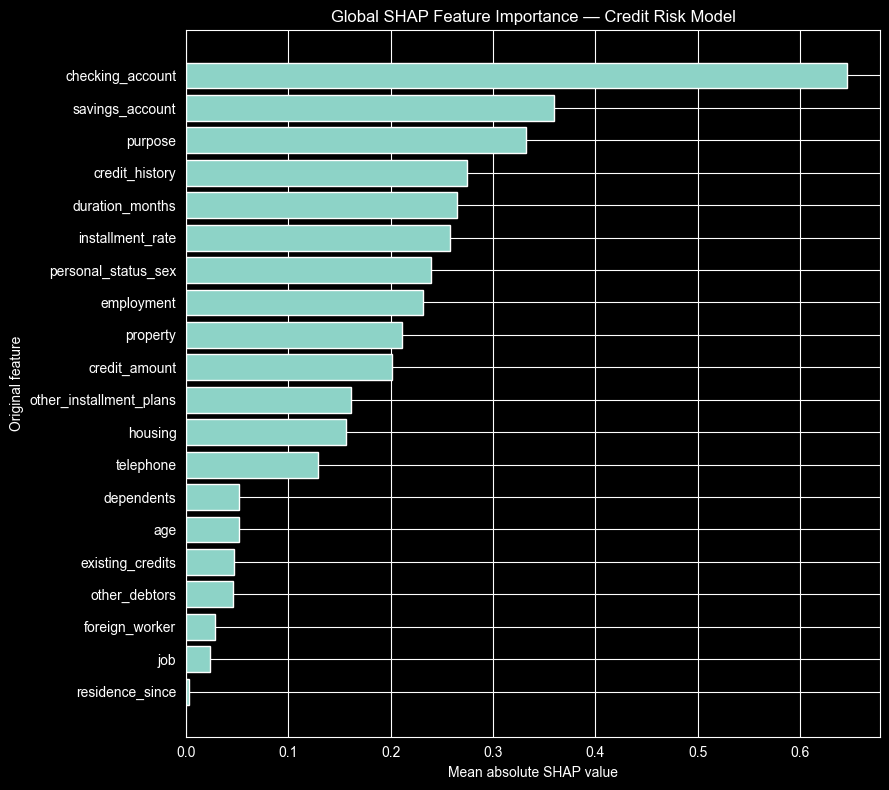

In [88]:
import matplotlib.pyplot as plt

plot_data = shap_by_original.sort_values(
    "mean_abs_shap",
    ascending=True
)

plt.figure(figsize=(9, 8))

plt.barh(
    plot_data["original_feature"],
    plot_data["mean_abs_shap"]
)

plt.xlabel("Mean absolute SHAP value")
plt.ylabel("Original feature")
plt.title("Global SHAP Feature Importance — Credit Risk Model")

plt.tight_layout()
plt.show()

In [89]:
# Predictions from the final Logistic Regression model
test_predictions = final_logistic_model.predict(X_test)
test_probabilities = final_logistic_model.predict_proba(X_test)[:, 1]

# Find applicants predicted as bad risk
bad_risk_indices = np.where(test_predictions == 1)[0]

print("Number predicted as bad risk:", len(bad_risk_indices))

# Select the first predicted bad-risk applicant
applicant_idx = bad_risk_indices[0]

print("Applicant index:", applicant_idx)
print("Actual target:", y_test.iloc[applicant_idx])
print("Predicted target:", test_predictions[applicant_idx])
print("Predicted bad-risk probability:", round(test_probabilities[applicant_idx], 3))

Number predicted as bad risk: 42
Applicant index: 2
Actual target: 1
Predicted target: 1
Predicted bad-risk probability: 0.558


In [90]:
# SHAP values for the selected applicant
applicant_shap = shap_values[applicant_idx]

# Create a dataframe linking features to SHAP contributions
local_explanation = pd.DataFrame({
    "feature": feature_names,
    "shap_value": applicant_shap
})

# Largest positive contributions → push toward bad risk
positive_contributions = (
    local_explanation
    .sort_values("shap_value", ascending=False)
    .head(10)
)

# Largest negative contributions → push toward good risk
negative_contributions = (
    local_explanation
    .sort_values("shap_value", ascending=True)
    .head(10)
)

print("Top factors pushing toward BAD risk:")
print(positive_contributions.to_string(index=False))

print("\nTop factors pushing toward GOOD risk:")
print(negative_contributions.to_string(index=False))

Top factors pushing toward BAD risk:
                                                              feature  shap_value
                                 categorical__checking_account_< 0 DM    0.381268
                    categorical__checking_account_No checking account    0.279021
                            categorical__other_installment_plans_None    0.259742
                                     categorical__employment_< 1 year    0.243649
                                          numerical__installment_rate    0.240913
                       categorical__personal_status_sex_Male - single    0.202739
                                categorical__savings_account_< 100 DM    0.164381
categorical__credit_history_Critical account / other existing credits    0.139336
                                           numerical__duration_months    0.067685
            categorical__savings_account_Unknown / no savings account    0.065816

Top factors pushing toward GOOD risk:
                      

In [91]:
applicant_original = X_test.iloc[applicant_idx]

print(applicant_original.to_string())

checking_account                                      < 0 DM
duration_months                                           24
credit_history             Delay in previous credit payments
purpose                                     Radio/television
credit_amount                                           1024
savings_account                                     < 100 DM
employment                                          < 1 year
installment_rate                                           4
personal_status_sex                   Male - married/widowed
other_debtors                                           None
residence_since                                            4
property                                         Real estate
age                                                       48
other_installment_plans                               Stores
housing                                                  Own
existing_credits                                           1
job                     

In [92]:
print("Selected applicant's original features:")
print(X_test.iloc[applicant_idx].to_string())

print("\nActual target:", y_test.iloc[applicant_idx])
print("Predicted target:", test_predictions[applicant_idx])
print("Predicted bad-risk probability:", round(test_probabilities[applicant_idx], 3))

Selected applicant's original features:
checking_account                                      < 0 DM
duration_months                                           24
credit_history             Delay in previous credit payments
purpose                                     Radio/television
credit_amount                                           1024
savings_account                                     < 100 DM
employment                                          < 1 year
installment_rate                                           4
personal_status_sex                   Male - married/widowed
other_debtors                                           None
residence_since                                            4
property                                         Real estate
age                                                       48
other_installment_plans                               Stores
housing                                                  Own
existing_credits                             

In [93]:
# Create original-feature mapping for the 61 transformed features

local_explanation = pd.DataFrame({
    "transformed_feature": feature_names,
    "shap_value": shap_values[applicant_idx],
    "original_feature": feature_mapping
})

# Aggregate SHAP contributions back to original variables
local_grouped = (
    local_explanation
    .groupby("original_feature", as_index=False)["shap_value"]
    .sum()
)

# Add the applicant's actual original value
applicant_values = X_test.iloc[applicant_idx]

local_grouped["actual_value"] = local_grouped["original_feature"].map(
    applicant_values
)

# Sort by absolute contribution
local_grouped["abs_shap"] = local_grouped["shap_value"].abs()

local_grouped = (
    local_grouped
    .sort_values("abs_shap", ascending=False)
    .drop(columns="abs_shap")
)

print(local_grouped.to_string(index=False))

       original_feature  shap_value                      actual_value
       checking_account    0.599733                            < 0 DM
             employment    0.313356                          < 1 year
other_installment_plans    0.242139                            Stores
       installment_rate    0.240913                                 4
        savings_account    0.230942                          < 100 DM
          credit_amount   -0.217701                              1024
               property   -0.205614                       Real estate
                purpose   -0.192912                  Radio/television
    personal_status_sex    0.144481            Male - married/widowed
              telephone    0.106886                              None
         credit_history    0.074926 Delay in previous credit payments
        duration_months    0.067685                                24
                housing   -0.066789                               Own
                    

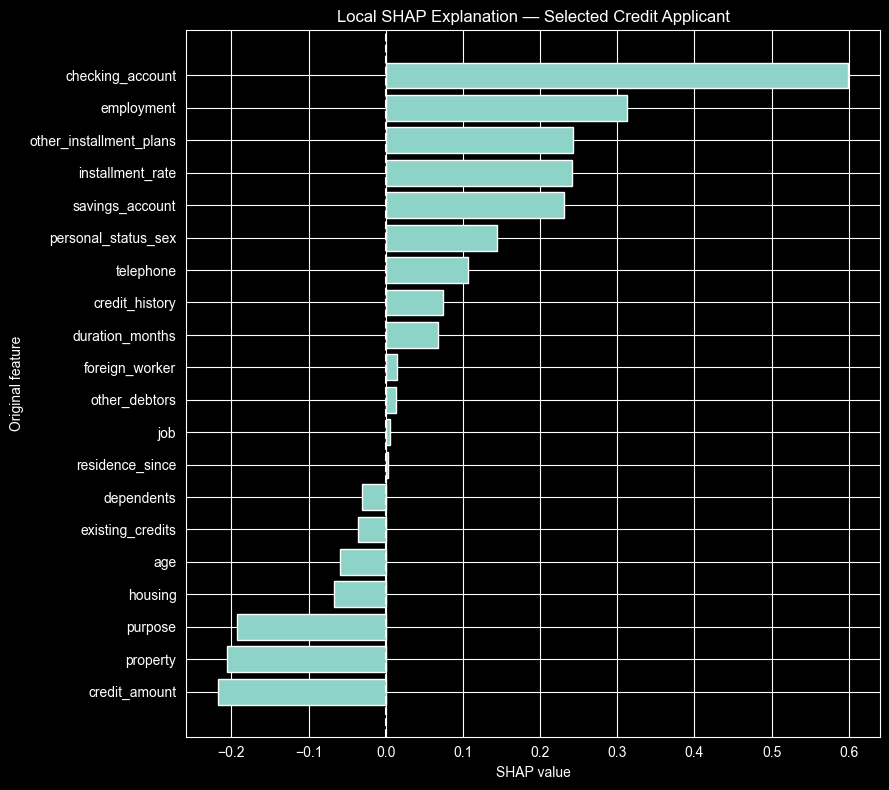

In [94]:
import matplotlib.pyplot as plt

local_plot = local_grouped.copy()

# Sort by SHAP contribution
local_plot = local_plot.sort_values("shap_value")

plt.figure(figsize=(9, 8))

plt.barh(
    local_plot["original_feature"],
    local_plot["shap_value"]
)

plt.axvline(0, linestyle="--")

plt.xlabel("SHAP value")
plt.ylabel("Original feature")
plt.title("Local SHAP Explanation — Selected Credit Applicant")

plt.tight_layout()
plt.show()

In [95]:
print("Personal status / sex:")
print(X_test["personal_status_sex"].value_counts())

print("\nForeign worker:")
print(X_test["foreign_worker"].value_counts())

print("\nAge summary:")
print(X_test["age"].describe())

Personal status / sex:
personal_status_sex
Male - single                          118
Female - divorced/separated/married     61
Male - married/widowed                  12
Male - divorced/separated                9
Name: count, dtype: int64

Foreign worker:
foreign_worker
Yes    194
No       6
Name: count, dtype: int64

Age summary:
count    200.000000
mean      36.435000
std       12.600781
min       20.000000
25%       26.000000
50%       33.000000
75%       43.250000
max       75.000000
Name: age, dtype: float64


In [96]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    confusion_matrix
)

# Combine actual and predicted results
fairness_df = X_test.copy()

fairness_df["actual"] = y_test.values
fairness_df["predicted"] = test_predictions

def calculate_group_metrics(group_df):
    y_true = group_df["actual"]
    y_pred = group_df["predicted"]

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    return pd.Series({
        "n": len(group_df),
        "precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "false_positive_rate": (
            fp / (fp + tn) if (fp + tn) > 0 else np.nan
        ),
        "false_negative_rate": (
            fn / (fn + tp) if (fn + tp) > 0 else np.nan
        )
    })

personal_status_metrics = (
    fairness_df
    .groupby("personal_status_sex")
    .apply(calculate_group_metrics, include_groups=False)
)

print(personal_status_metrics.round(3))

                                         n  precision  recall  \
personal_status_sex                                             
Female - divorced/separated/married   61.0      0.667   0.600   
Male - divorced/separated              9.0      0.750   1.000   
Male - married/widowed                12.0      1.000   0.667   
Male - single                        118.0      0.722   0.382   

                                     false_positive_rate  false_negative_rate  
personal_status_sex                                                            
Female - divorced/separated/married                0.146                0.400  
Male - divorced/separated                          0.167                0.000  
Male - married/widowed                             0.000                0.333  
Male - single                                      0.060                0.618  


In [97]:
foreign_worker_metrics = (
    fairness_df
    .groupby("foreign_worker")
    .apply(calculate_group_metrics, include_groups=False)
)

print(foreign_worker_metrics.round(3))

                    n  precision  recall  false_positive_rate  \
foreign_worker                                                  
No                6.0      1.000   1.000                0.000   
Yes             194.0      0.707   0.492                0.089   

                false_negative_rate  
foreign_worker                       
No                            0.000  
Yes                           0.508  


In [99]:
fairness_df["age_group"] = pd.cut(
    fairness_df["age"],
    bins=[0, 29, 44, float("inf")],
    labels=["Under 30", "30-44", "45+"]
)

age_metrics = (
    fairness_df
    .groupby("age_group", observed=False)
    .apply(calculate_group_metrics, include_groups=False)
)

print(age_metrics.round(3))

              n  precision  recall  false_positive_rate  false_negative_rate
age_group                                                                   
Under 30   79.0      0.783   0.529                0.111                0.471
30-44      73.0      0.667   0.444                0.073                0.556
45+        48.0      0.571   0.500                0.075                0.500


In [100]:
fairness_results = pd.concat([
    personal_status_metrics.reset_index().assign(
        group_type="Personal status / sex"
    ).rename(columns={"personal_status_sex": "group"}),

    foreign_worker_metrics.reset_index().assign(
        group_type="Foreign worker"
    ).rename(columns={"foreign_worker": "group"}),

    age_metrics.reset_index().assign(
        group_type="Age"
    ).rename(columns={"age_group": "group"})
], ignore_index=True)

print(fairness_results.round(3).to_string(index=False))

                              group     n  precision  recall  false_positive_rate  false_negative_rate            group_type
Female - divorced/separated/married  61.0      0.667   0.600                0.146                0.400 Personal status / sex
          Male - divorced/separated   9.0      0.750   1.000                0.167                0.000 Personal status / sex
             Male - married/widowed  12.0      1.000   0.667                0.000                0.333 Personal status / sex
                      Male - single 118.0      0.722   0.382                0.060                0.618 Personal status / sex
                                 No   6.0      1.000   1.000                0.000                0.000        Foreign worker
                                Yes 194.0      0.707   0.492                0.089                0.508        Foreign worker
                           Under 30  79.0      0.783   0.529                0.111                0.471                   Age


In [101]:
restricted_columns = [
    "personal_status_sex",
    "age",
    "foreign_worker"
]

X_restricted = X.drop(columns=restricted_columns)

print("Original feature count:", X.shape[1])
print("Restricted feature count:", X_restricted.shape[1])

Original feature count: 20
Restricted feature count: 17


In [102]:
X_train_restricted, X_test_restricted, y_train_restricted, y_test_restricted = train_test_split(
    X_restricted,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train_restricted.shape)
print("Test shape:", X_test_restricted.shape)

Training shape: (800, 17)
Test shape: (200, 17)


In [103]:
restricted_categorical_features = [
    feature for feature in categorical_features
    if feature not in restricted_columns
]

restricted_numerical_features = [
    feature for feature in numerical_features
    if feature not in restricted_columns
]

restricted_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            restricted_categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            restricted_numerical_features
        )
    ]
)

restricted_logistic_pipeline = Pipeline(
    steps=[
        ("preprocessor", restricted_preprocessor),
        (
            "model",
            LogisticRegression(
                C=logistic_grid.best_params_["model__C"],
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

In [104]:
restricted_logistic_pipeline.fit(
    X_train_restricted,
    y_train_restricted
)

restricted_predictions = restricted_logistic_pipeline.predict(
    X_test_restricted
)

restricted_probabilities = restricted_logistic_pipeline.predict_proba(
    X_test_restricted
)[:, 1]

print("Restricted Logistic Regression")
print("-" * 40)
print("Accuracy :",
      round(accuracy_score(y_test_restricted, restricted_predictions), 3))

print("Precision:",
      round(
          precision_score(
              y_test_restricted,
              restricted_predictions
          ),
          3
      ))

print("Recall   :",
      round(
          recall_score(
              y_test_restricted,
              restricted_predictions
          ),
          3
      ))

print("F1       :",
      round(
          f1_score(
              y_test_restricted,
              restricted_predictions
          ),
          3
      ))

print("ROC-AUC  :",
      round(
          roc_auc_score(
              y_test_restricted,
              restricted_probabilities
          ),
          3
      ))

print("Confusion Matrix:")
print(
    confusion_matrix(
        y_test_restricted,
        restricted_predictions
    )
)

Restricted Logistic Regression
----------------------------------------
Accuracy : 0.765
Precision: 0.686
Recall   : 0.4
F1       : 0.505
ROC-AUC  : 0.805
Confusion Matrix:
[[129  11]
 [ 36  24]]


In [105]:
restricted_fairness_df = X_test.copy()

restricted_fairness_df["actual"] = y_test_restricted.values
restricted_fairness_df["predicted"] = restricted_predictions

restricted_personal_metrics = (
    restricted_fairness_df
    .groupby("personal_status_sex")
    .apply(
        calculate_group_metrics,
        include_groups=False
    )
)

restricted_foreign_metrics = (
    restricted_fairness_df
    .groupby("foreign_worker")
    .apply(
        calculate_group_metrics,
        include_groups=False
    )
)

restricted_age_df = restricted_fairness_df.copy()

restricted_age_df["age_group"] = pd.cut(
    restricted_age_df["age"],
    bins=[0, 29, 44, float("inf")],
    labels=["Under 30", "30-44", "45+"]
)

restricted_age_metrics = (
    restricted_age_df
    .groupby("age_group", observed=False)
    .apply(
        calculate_group_metrics,
        include_groups=False
    )
)

print("PERSONAL STATUS / SEX")
print(restricted_personal_metrics.round(3))

print("\nFOREIGN WORKER")
print(restricted_foreign_metrics.round(3))

print("\nAGE")
print(restricted_age_metrics.round(3))

PERSONAL STATUS / SEX
                                         n  precision  recall  \
personal_status_sex                                             
Female - divorced/separated/married   61.0      0.636   0.350   
Male - divorced/separated              9.0      0.500   0.333   
Male - married/widowed                12.0      1.000   0.667   
Male - single                        118.0      0.700   0.412   

                                     false_positive_rate  false_negative_rate  
personal_status_sex                                                            
Female - divorced/separated/married                0.098                0.650  
Male - divorced/separated                          0.167                0.667  
Male - married/widowed                             0.000                0.333  
Male - single                                      0.071                0.588  

FOREIGN WORKER
                    n  precision  recall  false_positive_rate  \
foreign_worker            

In [107]:
responsible_ai_summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC"
    ],
    "Full_Model": [
        0.790,
        0.714,
        0.500,
        0.588,
        0.810
    ],
    "Restricted_Model": [
        0.765,
        0.686,
        0.400,
        0.505,
        0.805
    ]
})

print(responsible_ai_summary.to_string(index=False))

   Metric  Full_Model  Restricted_Model
 Accuracy       0.790             0.765
Precision       0.714             0.686
   Recall       0.500             0.400
       F1       0.588             0.505
  ROC-AUC       0.810             0.805
